# Agri-AI Bootcamp — Phase 1, Day 2
## Regression Models & Optimization

**Objective:** Build linear regression from scratch using NumPy, implement manual gradient descent, track Mean Squared Error (MSE), and visualize the loss curve.

### Course concepts
- Linear regression: a line fitted to predict a continuous target
- MSE: measures average squared prediction error
- Gradient descent: updates parameters in the direction that reduces loss
- Learning rate: controls the size of each update

### Agriculture application
The course example describes nitrogen fertilizer (kg/ha) → crop yield. The linked Kaggle dataset does not contain a nitrogen column in its commonly used CSV; this notebook therefore uses a selectable numeric feature (default rainfall) against yield. If you have a fertilizer dataset/column, change the selected feature accordingly. This is a learning exercise, not a causal estimate.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Upload the Kaggle dataset

In [11]:
from google.colab import files
uploaded = files.upload()

Saving yield_df.csv to yield_df (1).csv


In [12]:
import io
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (28242, 8)
Columns: ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


## 3. Select feature and target
The dataset typically has rainfall and yield columns, but not fertilizer nitrogen. Select a numeric feature to use as `x`. The code below attempts to use rainfall and yield column names commonly found in this Kaggle file; if names differ, update them after inspecting the columns.

In [13]:
# Adjust these column names if your CSV uses different names
feature_col = "average_rain_fall_mm_per_year"
target_col = "hg/ha_yield"

# Confirm column names exist
assert feature_col in df.columns, f"Feature column not found: {feature_col}"
assert target_col in df.columns, f"Target column not found: {target_col}"

data = df[[feature_col, target_col]].copy()
data = data.dropna()

# Numeric conversion
data[feature_col] = pd.to_numeric(data[feature_col], errors="coerce")
data[target_col] = pd.to_numeric(data[target_col], errors="coerce")
data = data.dropna().reset_index(drop=True)

print("Usable rows:", len(data))
display(data.head())

Usable rows: 28242


,average_rain_fall_mm_per_year,hg/ha_yield
0,1485.0,36613
1,1485.0,66667
2,1485.0,23333
3,1485.0,12500
4,1485.0,7000


## 4. Prepare arrays and train/test split

In [14]:
x = data[feature_col].to_numpy(dtype=float)
y = data[target_col].to_numpy(dtype=float)

# Reproducible 80/20 split, using pure NumPy
rng = np.random.default_rng(0)
idx = rng.permutation(len(x))
cut = int(0.8 * len(x))
tr, te = idx[:cut], idx[cut:]

x_train, x_test = x[tr], x[te]
y_train, y_test = y[tr], y[te]

print("Train rows:", len(tr))
print("Test rows:", len(te))

Train rows: 22593
Test rows: 5649


## 5. Scale the feature
Gradient descent can be unstable or slow when feature magnitudes are large. Standardize the input using training-set mean and standard deviation only. We then train on the standardized feature.

In [15]:
x_mean = x_train.mean()
x_std = x_train.std()
if x_std == 0:
    raise ValueError("Feature has zero variance; choose another feature.")

x_train_scaled = (x_train - x_mean) / x_std
x_test_scaled = (x_test - x_mean) / x_std

print("Training feature mean (scaled):", x_train_scaled.mean())
print("Training feature std (scaled):", x_train_scaled.std())

Training feature mean (scaled): 8.853086359335556e-17
Training feature std (scaled): 1.0


## 6. Linear regression from scratch with gradient descent

Model: `y_hat = w*x + b`

MSE: average of squared prediction errors.

Gradients:
- `dw = 2 * mean(error * x)`
- `db = 2 * mean(error)`

Each epoch updates `w` and `b` using the gradients. We store loss at every epoch to plot later.

In [16]:
w = 0.0
b = 0.0
lr = 0.01
epochs = 500

loss_history = []

for epoch in range(epochs):
    # Predictions and errors
    y_pred = w * x_train_scaled + b
    err = y_pred - y_train

    # MSE loss
    loss = np.mean(err ** 2)
    loss_history.append(loss)

    # Compute gradients
    dw = 2 * np.mean(err * x_train_scaled)
    db = 2 * np.mean(err)

    # Update parameters
    w -= lr * dw
    b -= lr * db

print("Final w:", w)
print("Final b:", b)
print("Final training MSE:", loss_history[-1])

Final w: -233.12628253961796
Final b: 76894.10969743002
Final training MSE: 7170411148.065031


## 7. Plot the loss curve

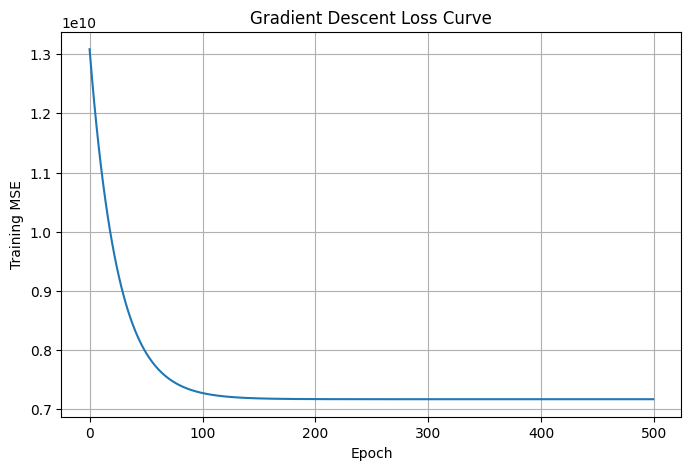

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Gradient Descent Loss Curve")
plt.grid(True)
plt.show()

## 8. Plot data and fitted regression line

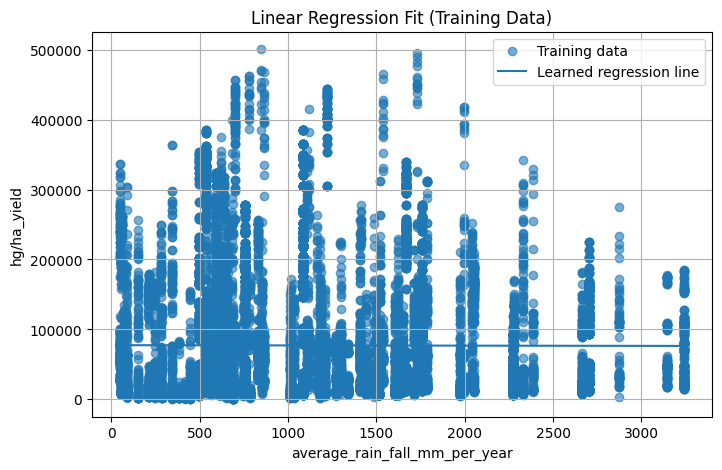

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, alpha=0.6, label="Training data")
x_line = np.linspace(x.min(), x.max(), 200)
x_line_scaled = (x_line - x_mean) / x_std
y_line = w * x_line_scaled + b
plt.plot(x_line, y_line, label="Learned regression line")
plt.xlabel(feature_col)
plt.ylabel(target_col)
plt.title("Linear Regression Fit (Training Data)")
plt.legend()
plt.grid(True)
plt.show()

## 9. Evaluate on held-out test data

In [19]:
y_test_pred = w * x_test_scaled + b
test_mse = np.mean((y_test_pred - y_test) ** 2)
test_rmse = np.sqrt(test_mse)

print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)

Test MSE: 7405774593.750987
Test RMSE: 86056.81026944345


## 10. Interpret the model

Because we standardized `x`, the learned `w` is the predicted yield change for a one-standard-deviation increase in the feature, not per one raw unit. `b` is the model's prediction at the training feature mean (since standardized x = 0 there).

If you want a raw-unit slope and intercept, convert:
- `raw_slope = w / x_std`
- `raw_intercept = b - raw_slope * x_mean`

For fertilizer example, a slope of 0.02 t/ha per kg N would imply that 50 kg N is associated with about 1 t/ha higher predicted yield within the data range; this interpretation is only valid for a model actually fitted to nitrogen and yield in matching units, and does not establish causality.

In [20]:
raw_slope = w / x_std
raw_intercept = b - raw_slope * x_mean

print("Slope in original feature units:", raw_slope)
print("Intercept in original feature units:", raw_intercept)
print(f"Equation: predicted yield = {raw_slope:.6f} * x + {raw_intercept:.6f}")

Slope in original feature units: -0.3291804077046747
Intercept in original feature units: 77271.7817026106
Equation: predicted yield = -0.329180 * x + 77271.781703


## 11. Learning-rate experiment (optional)
Compare a smaller and larger learning rate. Large rates can overshoot and cause oscillation or divergence; small rates may converge slowly. The feature was scaled above to improve stability.

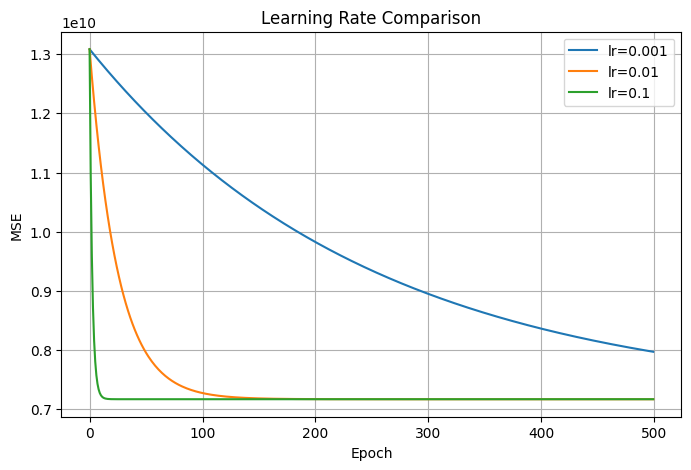

In [21]:
def run_gradient_descent(x_scaled, y_train, learning_rate, epochs=500):
    w = 0.0
    b = 0.0
    losses = []
    for _ in range(epochs):
        pred = w * x_scaled + b
        error = pred - y_train
        losses.append(np.mean(error ** 2))
        dw = 2 * np.mean(error * x_scaled)
        db = 2 * np.mean(error)
        w -= learning_rate * dw
        b -= learning_rate * db
    return w, b, losses

rates = [0.001, 0.01, 0.1]
plt.figure(figsize=(8, 5))
for rate in rates:
    _, _, losses = run_gradient_descent(x_train_scaled, y_train, rate, epochs=500)
    plt.plot(losses, label=f"lr={rate}")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Learning Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Conclusion
Linear regression was implemented from scratch using NumPy. Gradient descent updated the weight and bias using the gradients of MSE. The loss curve was plotted to observe optimization. The test-set metrics estimate performance on held-out observations. The feature selected from this dataset is [feature]; if using rainfall, the fitted association should not be interpreted as the causal effect of fertilizer or rainfall on yield.

